In [97]:
import os
import pandas as pd

drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET'

In [98]:
specific_file_name = 'INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2019_A_31-12-2019.CSV'
file_path = os.path.join(drive_path, specific_file_name)
print(f"\nAbrindo o arquivo especificado: '{file_path}'")

df = None
if specific_file_name.lower().endswith('.csv'):
    df = pd.read_csv(file_path, encoding='latin1', sep=';', skiprows=8)
elif specific_file_name.lower().endswith(('.xls', '.xlsx')):
    df = pd.read_excel(file_path)
else:
    print("Tipo de arquivo não suportado (apenas .csv, .xls, .xlsx são suportados por enquanto).")

if df is not None:
    print("\nColunas do DataFrame:")
    print(df.columns.tolist())
    print("\nPrimeiras 5 linhas do DataFrame:")
    display(df.head())


Abrindo o arquivo especificado: '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET/INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2019_A_31-12-2019.CSV'

Colunas do DataFrame:
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (KJ/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)', 'Unnamed: 19']

Primeiras 5 linhas do DataFrame:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (KJ/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)",Unnamed: 19
0,2019/01/01,0000 UTC,0,"926,8","926,8","926,3",NaN,"21,5","19,3","21,5","21,3","19,5",19,88,87,87.0,155,"5,9","2,3",NaN
1,2019/01/01,0100 UTC,0,"927,2","927,3","926,8",NaN,"21,1","18,9","21,6","21,1","19,6","18,9",88,85,87.0,118,"4,6","2,1",NaN
2,2019/01/01,0200 UTC,0,"926,9","927,4","926,9",NaN,"20,7",19,"21,1","20,3","19,1","18,7",91,87,90.0,110,"4,4","1,6",NaN
3,2019/01/01,0300 UTC,0,"926,2","926,9","926,2",NaN,"20,5","19,2","20,7","20,3","19,2","18,9",93,90,92.0,131,4,"1,7",NaN
4,2019/01/01,0400 UTC,0,"925,7","926,2","925,7",NaN,"20,7","19,5","20,9","20,3","19,6","19,1",93,92,93.0,155,"4,2","1,9",NaN


In [99]:
import os
import pandas as pd

drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET'
output_file_name = 'dados_inmet_combinados.csv'
output_file_path = os.path.join(drive_path, output_file_name)

# Colunas desejadas
desired_columns = [
    'Data',
    'Hora UTC',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)'
]

all_files = [f for f in os.listdir(drive_path) if f.lower().endswith('.csv')]
print(f"Encontrados {len(all_files)} arquivos CSV na pasta: {drive_path}")

dfs_to_concat = []

for file_name in all_files:
    file_path = os.path.join(drive_path, file_name)
    print(f"Processando arquivo: {file_name}")
    try:
        # Read with specified encoding, separator, and skip rows, similar to previous successful attempts
        df_temp = pd.read_csv(file_path, encoding='latin1', sep=';', skiprows=8)

        # Standardize column names (optional, but good practice if names vary slightly)
        # For now, we assume names are exact as requested. If not, mapping would be needed.

        # Select only the desired columns
        # Check if all desired columns exist before selecting
        existing_columns = [col for col in desired_columns if col in df_temp.columns]
        if len(existing_columns) == len(desired_columns):
            df_temp = df_temp[desired_columns]
            dfs_to_concat.append(df_temp)
        else:
            print(f"Aviso: O arquivo '{file_name}' não contém todas as colunas desejadas. Colunas faltando: {set(desired_columns) - set(df_temp.columns)}")

    except Exception as e:
        print(f"Erro ao ler o arquivo {file_name}: {e}")

if dfs_to_concat:
    combined_df = pd.concat(dfs_to_concat, ignore_index=True)
    print(f"Total de {len(dfs_to_concat)} arquivos combinados. DataFrame resultante com {len(combined_df)} linhas e {len(combined_df.columns)} colunas.")

    # Save the combined DataFrame to a new CSV file
    combined_df.to_csv(output_file_path, index=False, encoding='utf-8') # Using utf-8 for output
    print(f"Dados combinados salvos em: {output_file_path}")

    print("\nPrimeiras 5 linhas do DataFrame combinado:")
    display(combined_df.head())
else:
    print("Nenhum DataFrame foi combinado. Verifique se os arquivos estão corretos e contêm as colunas desejadas.")

Encontrados 12 arquivos CSV na pasta: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2025_A_31-12-2025.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2024_A_31-12-2024.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2023_A_31-12-2023.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2022_A_31-12-2022.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2021_A_31-12-2021.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2020_A_31-12-2020.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_01-01-2019_A_31-12-2019.CSV
Processando arquivo: INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_14-03-2018_A_31-12-2018.CSV
Aviso: O arquivo 'INMET_SE_SP_A771_SAO PAULO - INTERLAGOS_14-03-2018_A_31-12-2018.CSV' não contém todas as colunas desejadas. Colunas faltando: {'Data', 'Hora UTC'}
Processando arquivo: INMET_S

,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),"UMIDADE RELATIVA DO AR, HORARIA (%)"
0,2025/01/01,0000 UTC,0,"20,4","19,6",92.0
1,2025/01/01,0100 UTC,0,"19,9","19,3",94.0
2,2025/01/01,0200 UTC,0,"19,5","19,2",94.0
3,2025/01/01,0300 UTC,0,"19,4",19,95.0
4,2025/01/01,0400 UTC,0,"19,5","19,1",93.0


In [100]:
# Replace comma with dot in 'UMIDADE RELATIVA DO AR, HORARIA (%)' column
combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'] = combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'].astype(str).str.replace(',', '.', regex=False)

# Convert the column to numeric type, coercing errors to NaN
combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'] = pd.to_numeric(combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'], errors='coerce')

# Convert to nullable integer type to display whole numbers without .0 and handle NaNs
combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'] = combined_df['UMIDADE RELATIVA DO AR, HORARIA (%)'].astype('Int64')

print("\nInformações do DataFrame após a conversão da coluna:")
combined_df.info()

print("\nPrimeiras 5 linhas do DataFrame com a coluna atualizada:")
display(combined_df.head())


Informações do DataFrame após a conversão da coluna:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67200 entries, 0 to 67199
Data columns (total 6 columns):
 #   Column                                      Non-Null Count  Dtype 
---  ------                                      --------------  ----- 
 0   Data                                        67200 non-null  object
 1   Hora UTC                                    67200 non-null  object
 2   PRECIPITAÇÃO TOTAL, HORÁRIO (mm)            66500 non-null  object
 3   TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)  66009 non-null  object
 4   TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)  66010 non-null  object
 5   UMIDADE RELATIVA DO AR, HORARIA (%)         65641 non-null  Int64 
dtypes: Int64(1), object(5)
memory usage: 3.1+ MB

Primeiras 5 linhas do DataFrame com a coluna atualizada:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),"UMIDADE RELATIVA DO AR, HORARIA (%)"
0,2025/01/01,0000 UTC,0,"20,4","19,6",92
1,2025/01/01,0100 UTC,0,"19,9","19,3",94
2,2025/01/01,0200 UTC,0,"19,5","19,2",94
3,2025/01/01,0300 UTC,0,"19,4",19,95
4,2025/01/01,0400 UTC,0,"19,5","19,1",93


In [101]:
print("\nIniciando a conversão de outras colunas para numérico...")

for col in combined_df.columns:
    # Skip columns that are already numeric or datetime (if any were converted)
    if pd.api.types.is_numeric_dtype(combined_df[col]) or pd.api.types.is_datetime64_any_dtype(combined_df[col]):
        continue

    # Convert to string type first to ensure .str accessor works
    temp_col = combined_df[col].astype(str)

    # Check if the column contains commas, indicating a potential numeric column with ',' as decimal separator
    # And also check if it's not a 'Data' or 'Hora UTC' column
    if temp_col.str.contains(',', na=False).any() and col not in ['Data', 'Hora UTC']:
        print(f"Processando coluna: '{col}'")
        # Replace comma with dot
        temp_col = temp_col.str.replace(',', '.', regex=False)

        # Attempt to convert to numeric, coercing errors to NaN
        converted_col = pd.to_numeric(temp_col, errors='coerce')

        # If a significant number of values were successfully converted, update the column
        # We can define 'significant' as having fewer NaNs after conversion than before (or at least some non-NaNs)
        # Or simply update if conversion created any valid numbers
        if not converted_col.isnull().all(): # Check if at least some values became non-null numbers
            combined_df[col] = converted_col
            print(f"Coluna '{col}' convertida para tipo numérico.")
        else:
            print(f"Aviso: Coluna '{col}' contém valores não numéricos que não puderam ser convertidos mesmo após a substituição da vírgula. Mantendo como tipo original.")

# Convert 'Data' column to datetime objects
combined_df['Data'] = pd.to_datetime(combined_df['Data'], format='%Y/%m/%d')

print("\nInformações finais do DataFrame após todas as conversões:")
combined_df.info()

print("\nPrimeiras 5 linhas do DataFrame com todas as colunas atualizadas:")
display(combined_df.head())


Iniciando a conversão de outras colunas para numérico...
Processando coluna: 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
Coluna 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)' convertida para tipo numérico.
Processando coluna: 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)'
Coluna 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)' convertida para tipo numérico.
Processando coluna: 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)'
Coluna 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)' convertida para tipo numérico.

Informações finais do DataFrame após todas as conversões:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67200 entries, 0 to 67199
Data columns (total 6 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   Data                                        67200 non-null  datetime64[ns]
 1   Hora UTC                                    67200 non-null  object        
 2   PRECIPITAÇÃO TOTAL, HORÁRI

,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),"UMIDADE RELATIVA DO AR, HORARIA (%)"
0,2025-01-01,0000 UTC,0.0,20.4,19.6,92
1,2025-01-01,0100 UTC,0.0,19.9,19.3,94
2,2025-01-01,0200 UTC,0.0,19.5,19.2,94
3,2025-01-01,0300 UTC,0.0,19.4,19.0,95
4,2025-01-01,0400 UTC,0.0,19.5,19.1,93


In [102]:
combined_df.to_csv(output_file_path, index=False, encoding='utf-8')
print(f"DataFrame atualizado salvo em: {output_file_path}")

DataFrame atualizado salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET/dados_inmet_combinados.csv


In [103]:
drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INEP'

In [104]:
specific_file_name_inep = 'MICRODADOS_CADASTRO_CURSOS_2018_LIMPO.CSV'
file_path_inep = os.path.join(drive_path, specific_file_name_inep)
print(f"\nCarregando o arquivo: '{file_path_inep}'")

df_inep = pd.read_csv(file_path_inep, encoding='latin1', sep=';') # Assuming same encoding and separator as previous INMET files

print("\nColunas do DataFrame INEP:")
print(df_inep.columns.tolist())
print("\nPrimeiras 5 linhas do DataFrame INEP:")
display(df_inep.head())


Carregando o arquivo: '/content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/MICRODADOS_CADASTRO_CURSOS_2018_LIMPO.CSV'

Colunas do DataFrame INEP:
['NU_ANO_CENSO', 'SG_UF', 'NO_MUNICIPIO', 'CO_MUNICIPIO', 'CO_IES', 'NO_CURSO', 'NO_CINE_AREA_GERAL', 'QT_VG_TOTAL', 'QT_INSCRITO_TOTAL', 'QT_ING', 'QT_MAT', 'QT_CONC', 'QT_SIT_TRANCADA', 'QT_SIT_FALECIDO']

Primeiras 5 linhas do DataFrame INEP:


,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA,QT_SIT_FALECIDO
0,2018,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40.0,11.0,50.0,2.0,0.0,0.0
1,2018,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50.0,114.0,42.0,194.0,39.0,0.0,0.0
2,2018,RO,Ariquemes,1100023.0,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55.0,49.0,115.0,20.0,220.0,0.0
3,2018,RO,Ariquemes,1100023.0,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40.0,29.0,54.0,0.0,35.0,0.0
4,2018,RO,Ariquemes,1100023.0,1540,DIREITO,"Negócios, administração e direito",100.0,100.0,102.0,453.0,71.0,287.0,0.0


In [105]:
if 'QT_SIT_FALECIDO' in df_inep.columns:
    df_inep = df_inep.drop(columns=['QT_SIT_FALECIDO'])
    print("Coluna 'QT_SIT_FALECIDO' removida com sucesso.")
else:
    print("A coluna 'QT_SIT_FALECIDO' não foi encontrada no DataFrame.")

print("\nColunas do DataFrame INEP após a remoção:")
print(df_inep.columns.tolist())
print("\nPrimeiras 5 linhas do DataFrame INEP após a remoção:")
display(df_inep.head())

Coluna 'QT_SIT_FALECIDO' removida com sucesso.

Colunas do DataFrame INEP após a remoção:
['NU_ANO_CENSO', 'SG_UF', 'NO_MUNICIPIO', 'CO_MUNICIPIO', 'CO_IES', 'NO_CURSO', 'NO_CINE_AREA_GERAL', 'QT_VG_TOTAL', 'QT_INSCRITO_TOTAL', 'QT_ING', 'QT_MAT', 'QT_CONC', 'QT_SIT_TRANCADA']

Primeiras 5 linhas do DataFrame INEP após a remoção:


,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40.0,11.0,50.0,2.0,0.0
1,2018,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50.0,114.0,42.0,194.0,39.0,0.0
2,2018,RO,Ariquemes,1100023.0,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55.0,49.0,115.0,20.0,220.0
3,2018,RO,Ariquemes,1100023.0,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40.0,29.0,54.0,0.0,35.0
4,2018,RO,Ariquemes,1100023.0,1540,DIREITO,"Negócios, administração e direito",100.0,100.0,102.0,453.0,71.0,287.0


In [106]:
df_inep['SG_UF'] = df_inep['SG_UF'].fillna('Desconhecido')
df_inep['NO_MUNICIPIO'] = df_inep['NO_MUNICIPIO'].fillna('Desconhecido')

print("\nInformações do DataFrame INEP após preencher valores vazios:")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP após preencher valores vazios:")
display(df_inep.head())


Informações do DataFrame INEP após preencher valores vazios:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   NU_ANO_CENSO        182892 non-null  int64  
 1   SG_UF               182892 non-null  object 
 2   NO_MUNICIPIO        182892 non-null  object 
 3   CO_MUNICIPIO        179625 non-null  float64
 4   CO_IES              182892 non-null  int64  
 5   NO_CURSO            182892 non-null  object 
 6   NO_CINE_AREA_GERAL  182892 non-null  object 
 7   QT_VG_TOTAL         38256 non-null   float64
 8   QT_INSCRITO_TOTAL   38256 non-null   float64
 9   QT_ING              179712 non-null  float64
 10  QT_MAT              179712 non-null  float64
 11  QT_CONC             179712 non-null  float64
 12  QT_SIT_TRANCADA     179712 non-null  float64
dtypes: float64(7), int64(2), object(4)
memory usage: 18.1+ MB

Primeiras 5 l

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40.0,11.0,50.0,2.0,0.0
1,2018,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50.0,114.0,42.0,194.0,39.0,0.0
2,2018,RO,Ariquemes,1100023.0,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55.0,49.0,115.0,20.0,220.0
3,2018,RO,Ariquemes,1100023.0,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40.0,29.0,54.0,0.0,35.0
4,2018,RO,Ariquemes,1100023.0,1540,DIREITO,"Negócios, administração e direito",100.0,100.0,102.0,453.0,71.0,287.0


In [107]:
print("\nPreenchendo valores vazios na coluna 'QT_VG_TOTAL' com a média agrupada por 'SG_UF' e 'NO_MUNICIPIO'...")

df_inep['QT_VG_TOTAL'] = df_inep.groupby(['SG_UF', 'NO_MUNICIPIO'])['QT_VG_TOTAL'].transform(lambda x: x.fillna(x.mean()))

print("\nInformações do DataFrame INEP após preencher 'QT_VG_TOTAL':")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP após preencher 'QT_VG_TOTAL':")
display(df_inep.head())


Preenchendo valores vazios na coluna 'QT_VG_TOTAL' com a média agrupada por 'SG_UF' e 'NO_MUNICIPIO'...

Informações do DataFrame INEP após preencher 'QT_VG_TOTAL':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   NU_ANO_CENSO        182892 non-null  int64  
 1   SG_UF               182892 non-null  object 
 2   NO_MUNICIPIO        182892 non-null  object 
 3   CO_MUNICIPIO        179625 non-null  float64
 4   CO_IES              182892 non-null  int64  
 5   NO_CURSO            182892 non-null  object 
 6   NO_CINE_AREA_GERAL  182892 non-null  object 
 7   QT_VG_TOTAL         160700 non-null  float64
 8   QT_INSCRITO_TOTAL   38256 non-null   float64
 9   QT_ING              179712 non-null  float64
 10  QT_MAT              179712 non-null  float64
 11  QT_CONC             179712 non-null  float64
 12  QT_SIT_TRANCADA   

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40.0,11.0,50.0,2.0,0.0
1,2018,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50.0,114.0,42.0,194.0,39.0,0.0
2,2018,RO,Ariquemes,1100023.0,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55.0,49.0,115.0,20.0,220.0
3,2018,RO,Ariquemes,1100023.0,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40.0,29.0,54.0,0.0,35.0
4,2018,RO,Ariquemes,1100023.0,1540,DIREITO,"Negócios, administração e direito",100.0,100.0,102.0,453.0,71.0,287.0


In [108]:
output_file_name_inep = 'dados_inep_2018_tratados.csv'
output_file_path_inep = os.path.join(drive_path, output_file_name_inep)

df_inep.to_csv(output_file_path_inep, index=False, encoding='utf-8')
print(f"DataFrame INEP atualizado salvo em: {output_file_path_inep}")

DataFrame INEP atualizado salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2018_tratados.csv


### Corrigindo o DataFrame `df_inep`

Recarregando o DataFrame do arquivo original para desfazer as alterações indesejadas e reaplicando apenas os passos corretos.

In [109]:
print(f"\nRecarregando o arquivo: '{file_path_inep}' para desfazer as alterações...")
df_inep = pd.read_csv(file_path_inep, encoding='latin1', sep=';') # Recarregando do arquivo original

# Removendo a coluna 'QT_SIT_FALECIDO' novamente
if 'QT_SIT_FALECIDO' in df_inep.columns:
    df_inep = df_inep.drop(columns=['QT_SIT_FALECIDO'])
    print("Coluna 'QT_SIT_FALECIDO' removida com sucesso após recarga.")

# Reaplicando o preenchimento de 'SG_UF' e 'NO_MUNICIPIO'
df_inep['SG_UF'] = df_inep['SG_UF'].fillna('Desconhecido')
df_inep['NO_MUNICIPIO'] = df_inep['NO_MUNICIPIO'].fillna('Desconhecido')

print("\nInformações do DataFrame INEP após correção e preenchimento de SG_UF e NO_MUNICIPIO:")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP corrigido:")
display(df_inep.head())


Recarregando o arquivo: '/content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/MICRODADOS_CADASTRO_CURSOS_2018_LIMPO.CSV' para desfazer as alterações...
Coluna 'QT_SIT_FALECIDO' removida com sucesso após recarga.

Informações do DataFrame INEP após correção e preenchimento de SG_UF e NO_MUNICIPIO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   NU_ANO_CENSO        182892 non-null  int64  
 1   SG_UF               182892 non-null  object 
 2   NO_MUNICIPIO        182892 non-null  object 
 3   CO_MUNICIPIO        179625 non-null  float64
 4   CO_IES              182892 non-null  int64  
 5   NO_CURSO            182892 non-null  object 
 6   NO_CINE_AREA_GERAL  182892 non-null  object 
 7   QT_VG_TOTAL         38256 non-null   float64
 8   QT_INSCRITO_TOTAL   38256 non-null   float64
 9   QT_ING              179712 non-n

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40.0,11.0,50.0,2.0,0.0
1,2018,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50.0,114.0,42.0,194.0,39.0,0.0
2,2018,RO,Ariquemes,1100023.0,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55.0,49.0,115.0,20.0,220.0
3,2018,RO,Ariquemes,1100023.0,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40.0,29.0,54.0,0.0,35.0
4,2018,RO,Ariquemes,1100023.0,1540,DIREITO,"Negócios, administração e direito",100.0,100.0,102.0,453.0,71.0,287.0


In [110]:
output_file_name_inep = 'dados_inep_2018_tratados.csv'
output_file_path_inep = os.path.join(drive_path, output_file_name_inep)

df_inep.to_csv(output_file_path_inep, index=False, encoding='utf-8')
print(f"DataFrame INEP corrigido salvo em: {output_file_path_inep}")

DataFrame INEP corrigido salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2018_tratados.csv


### Melhorando a apresentação de números decimais

Convertendo colunas `float64` para `Int64` para exibir números inteiros sem `.0` e ainda tratar `NaN`.

In [111]:
print("\nConvertendo colunas numéricas para formato inteiro...")

for col in df_inep.select_dtypes(include=['float64']).columns:
    # Only attempt conversion if the column contains values that can be represented as integers
    # Check if all non-NaN values are effectively integers (e.g., 70.0)
    if df_inep[col].dropna().apply(lambda x: x.is_integer()).all():
        df_inep[col] = df_inep[col].astype('Int64')
        print(f"Coluna '{col}' convertida para Int64.")
    else:
        print(f"Coluna '{col}' contém valores decimais ou outros tipos que impedem a conversão para Int64, mantendo como float64.")

print("\nInformações do DataFrame INEP após a melhoria na apresentação numérica:")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP com números atualizados:")
display(df_inep.head())


Convertendo colunas numéricas para formato inteiro...
Coluna 'CO_MUNICIPIO' convertida para Int64.
Coluna 'QT_VG_TOTAL' convertida para Int64.
Coluna 'QT_INSCRITO_TOTAL' convertida para Int64.
Coluna 'QT_ING' convertida para Int64.
Coluna 'QT_MAT' convertida para Int64.
Coluna 'QT_CONC' convertida para Int64.
Coluna 'QT_SIT_TRANCADA' convertida para Int64.

Informações do DataFrame INEP após a melhoria na apresentação numérica:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NU_ANO_CENSO        182892 non-null  int64 
 1   SG_UF               182892 non-null  object
 2   NO_MUNICIPIO        182892 non-null  object
 3   CO_MUNICIPIO        179625 non-null  Int64 
 4   CO_IES              182892 non-null  int64 
 5   NO_CURSO            182892 non-null  object
 6   NO_CINE_AREA_GERAL  182892 non-null  object
 7   QT_VG_TOTA

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70,40,11,50,2,0
1,2018,RO,Ariquemes,1100023,699,PEDAGOGIA,Educação,50,114,42,194,39,0
2,2018,RO,Ariquemes,1100023,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100,55,49,115,20,220
3,2018,RO,Ariquemes,1100023,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100,40,29,54,0,35
4,2018,RO,Ariquemes,1100023,1540,DIREITO,"Negócios, administração e direito",100,100,102,453,71,287


### Preenchendo valores ausentes em `QT_VG_TOTAL` com a média por `SG_UF`

In [112]:
print("\nPreenchendo valores vazios na coluna 'QT_VG_TOTAL' com a média agrupada por 'SG_UF'...")

# Converter para float64 temporariamente para permitir o preenchimento com médias decimais
df_inep['QT_VG_TOTAL'] = df_inep['QT_VG_TOTAL'].astype('float64')

df_inep['QT_VG_TOTAL'] = df_inep.groupby('SG_UF')['QT_VG_TOTAL'].transform(lambda x: x.fillna(x.mean()))

print("\nInformações do DataFrame INEP após preencher 'QT_VG_TOTAL':")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP após preencher 'QT_VG_TOTAL':")
display(df_inep.head())


Preenchendo valores vazios na coluna 'QT_VG_TOTAL' com a média agrupada por 'SG_UF'...

Informações do DataFrame INEP após preencher 'QT_VG_TOTAL':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   NU_ANO_CENSO        182892 non-null  int64  
 1   SG_UF               182892 non-null  object 
 2   NO_MUNICIPIO        182892 non-null  object 
 3   CO_MUNICIPIO        179625 non-null  Int64  
 4   CO_IES              182892 non-null  int64  
 5   NO_CURSO            182892 non-null  object 
 6   NO_CINE_AREA_GERAL  182892 non-null  object 
 7   QT_VG_TOTAL         182892 non-null  float64
 8   QT_INSCRITO_TOTAL   38256 non-null   Int64  
 9   QT_ING              179712 non-null  Int64  
 10  QT_MAT              179712 non-null  Int64  
 11  QT_CONC             179712 non-null  Int64  
 12  QT_SIT_TRANCADA     179712 non-null

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70.0,40,11,50,2,0
1,2018,RO,Ariquemes,1100023,699,PEDAGOGIA,Educação,50.0,114,42,194,39,0
2,2018,RO,Ariquemes,1100023,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100.0,55,49,115,20,220
3,2018,RO,Ariquemes,1100023,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100.0,40,29,54,0,35
4,2018,RO,Ariquemes,1100023,1540,DIREITO,"Negócios, administração e direito",100.0,100,102,453,71,287


### Arredondando e convertendo `QT_VG_TOTAL` para inteiro

In [113]:
print("\nArredondando 'QT_VG_TOTAL' para o inteiro mais próximo e convertendo para Int64...")

# Arredondar para o inteiro mais próximo
df_inep['QT_VG_TOTAL'] = df_inep['QT_VG_TOTAL'].round()

# Converter para Int64 para armazenar inteiros e lidar com nulos (se houver)
df_inep['QT_VG_TOTAL'] = df_inep['QT_VG_TOTAL'].astype('Int64')

print("\nInformações do DataFrame INEP após arredondar e converter 'QT_VG_TOTAL':")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP com 'QT_VG_TOTAL' atualizada:")
display(df_inep.head())


Arredondando 'QT_VG_TOTAL' para o inteiro mais próximo e convertendo para Int64...

Informações do DataFrame INEP após arredondar e converter 'QT_VG_TOTAL':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NU_ANO_CENSO        182892 non-null  int64 
 1   SG_UF               182892 non-null  object
 2   NO_MUNICIPIO        182892 non-null  object
 3   CO_MUNICIPIO        179625 non-null  Int64 
 4   CO_IES              182892 non-null  int64 
 5   NO_CURSO            182892 non-null  object
 6   NO_CINE_AREA_GERAL  182892 non-null  object
 7   QT_VG_TOTAL         182892 non-null  Int64 
 8   QT_INSCRITO_TOTAL   38256 non-null   Int64 
 9   QT_ING              179712 non-null  Int64 
 10  QT_MAT              179712 non-null  Int64 
 11  QT_CONC             179712 non-null  Int64 
 12  QT_SIT_TRANCADA     179712 non-null  Int

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70,40,11,50,2,0
1,2018,RO,Ariquemes,1100023,699,PEDAGOGIA,Educação,50,114,42,194,39,0
2,2018,RO,Ariquemes,1100023,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100,55,49,115,20,220
3,2018,RO,Ariquemes,1100023,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100,40,29,54,0,35
4,2018,RO,Ariquemes,1100023,1540,DIREITO,"Negócios, administração e direito",100,100,102,453,71,287


### Salvando o DataFrame INEP com as últimas correções

In [114]:
output_file_name_inep = 'dados_inep_2018_tratados.csv'
output_file_path_inep = os.path.join(drive_path, output_file_name_inep)

df_inep.to_csv(output_file_path_inep, index=False, encoding='utf-8')
print(f"DataFrame INEP atualizado salvo em: {output_file_path_inep}")

DataFrame INEP atualizado salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2018_tratados.csv


### Preenchendo valores ausentes nas demais colunas numéricas com a média por `SG_UF`

In [115]:
print("\nPreenchendo valores vazios nas colunas numéricas restantes com a média agrupada por 'SG_UF'...")

columns_to_impute = [
    'QT_INSCRITO_TOTAL',
    'QT_ING',
    'QT_MAT',
    'QT_CONC',
    'QT_SIT_TRANCADA'
]

for col in columns_to_impute:
    if col in df_inep.columns:
        print(f"Processando coluna: '{col}'")
        # Converter para float64 temporariamente para permitir o preenchimento com médias decimais
        df_inep[col] = df_inep[col].astype('float64')

        # Preencher valores nulos com a média agrupada por SG_UF
        df_inep[col] = df_inep.groupby('SG_UF')[col].transform(lambda x: x.fillna(x.mean()))

        # Arredondar para o inteiro mais próximo e converter para Int64
        df_inep[col] = df_inep[col].round()
        df_inep[col] = df_inep[col].astype('Int64')
    else:
        print(f"Aviso: Coluna '{col}' não encontrada no DataFrame.")


print("\nInformações do DataFrame INEP após preencher as colunas restantes:")
df_inep.info()

print("\nPrimeiras 5 linhas do DataFrame INEP com as colunas atualizadas:")
display(df_inep.head())


Preenchendo valores vazios nas colunas numéricas restantes com a média agrupada por 'SG_UF'...
Processando coluna: 'QT_INSCRITO_TOTAL'
Processando coluna: 'QT_ING'
Processando coluna: 'QT_MAT'
Processando coluna: 'QT_CONC'
Processando coluna: 'QT_SIT_TRANCADA'

Informações do DataFrame INEP após preencher as colunas restantes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182892 entries, 0 to 182891
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NU_ANO_CENSO        182892 non-null  int64 
 1   SG_UF               182892 non-null  object
 2   NO_MUNICIPIO        182892 non-null  object
 3   CO_MUNICIPIO        179625 non-null  Int64 
 4   CO_IES              182892 non-null  int64 
 5   NO_CURSO            182892 non-null  object
 6   NO_CINE_AREA_GERAL  182892 non-null  object
 7   QT_VG_TOTAL         182892 non-null  Int64 
 8   QT_INSCRITO_TOTAL   182892 non-null  Int64 
 9   QT_ING         

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2018,RO,Ariquemes,1100023,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70,40,11,50,2,0
1,2018,RO,Ariquemes,1100023,699,PEDAGOGIA,Educação,50,114,42,194,39,0
2,2018,RO,Ariquemes,1100023,1540,ADMINISTRAÇÃO,"Negócios, administração e direito",100,55,49,115,20,220
3,2018,RO,Ariquemes,1100023,1540,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",100,40,29,54,0,35
4,2018,RO,Ariquemes,1100023,1540,DIREITO,"Negócios, administração e direito",100,100,102,453,71,287


### Salvando o DataFrame INEP com todas as últimas correções

In [116]:
output_file_name_inep = 'dados_inep_2018_tratados.csv'
output_file_path_inep = os.path.join(drive_path, output_file_name_inep)

df_inep.to_csv(output_file_path_inep, index=False, encoding='utf-8')
print(f"DataFrame INEP atualizado salvo em: {output_file_path_inep}")

DataFrame INEP atualizado salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2018_tratados.csv


### Processando múltiplos arquivos INEP de 2019 a 2024

In [117]:
import os
import pandas as pd

# Caminho base para os arquivos
drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INEP'

# Lista de anos a serem processados
years_to_process = range(2019, 2025) # Inclui 2019, 2020, ..., 2024

# Colunas numéricas que devem ser tratadas (preenchimento de NaN e conversão para Int64)
numeric_cols_to_impute = [
    'QT_VG_TOTAL',
    'QT_INSCRITO_TOTAL',
    'QT_ING',
    'QT_MAT',
    'QT_CONC',
    'QT_SIT_TRANCADA'
]

for year in years_to_process:
    specific_file_name_inep = f'MICRODADOS_CADASTRO_CURSOS_{year}_LIMPO.CSV'
    file_path_inep = os.path.join(drive_path, specific_file_name_inep)

    print(f"\n{'='*50}")
    print(f"Processando arquivo: {specific_file_name_inep}")
    print(f"{'='*50}")

    if not os.path.exists(file_path_inep):
        print(f"Aviso: Arquivo não encontrado: {file_path_inep}. Pulando este ano.")
        continue

    try:
        df_inep_current = pd.read_csv(file_path_inep, encoding='latin1', sep=';')
        print(f"Arquivo '{specific_file_name_inep}' carregado com sucesso.")

        # 1. Remover coluna 'QT_SIT_FALECIDO'
        if 'QT_SIT_FALECIDO' in df_inep_current.columns:
            df_inep_current = df_inep_current.drop(columns=['QT_SIT_FALECIDO'])
            print("Coluna 'QT_SIT_FALECIDO' removida.")

        # 2. Preencher valores ausentes em 'SG_UF' e 'NO_MUNICIPIO'
        df_inep_current['SG_UF'] = df_inep_current['SG_UF'].fillna('Desconhecido')
        df_inep_current['NO_MUNICIPIO'] = df_inep_current['NO_MUNICIPIO'].fillna('Desconhecido')
        print("Valores ausentes em 'SG_UF' e 'NO_MUNICIPIO' preenchidos.")

        # 3. Tratar CO_IES: converter para 'object' e preencher NaNs com 'Desconhecido'
        if 'CO_IES' in df_inep_current.columns:
            df_inep_current['CO_IES'] = df_inep_current['CO_IES'].astype('object')
            df_inep_current['CO_IES'] = df_inep_current['CO_IES'].fillna('Desconhecido')
            print("Coluna 'CO_IES' convertida para 'object' e NaNs preenchidos.")

        # 4. Tratar CO_MUNICIPIO: converter para 'object' e preencher NaNs com 'Desconhecido'
        if 'CO_MUNICIPIO' in df_inep_current.columns:
            df_inep_current['CO_MUNICIPIO'] = df_inep_current['CO_MUNICIPIO'].astype('object')
            df_inep_current['CO_MUNICIPIO'] = df_inep_current['CO_MUNICIPIO'].fillna('Desconhecido')
            print("Coluna 'CO_MUNICIPIO' convertida para 'object' e NaNs preenchidos.")

        # 5. Tratar colunas numéricas (preencher NaN com média por SG_UF e converter para Int64)
        for col in numeric_cols_to_impute:
            if col in df_inep_current.columns:
                # Converter para float64 temporariamente para permitir o preenchimento com médias decimais
                df_inep_current[col] = df_inep_current[col].astype('float64')

                # Preencher valores nulos com a média agrupada por SG_UF
                df_inep_current[col] = df_inep_current.groupby('SG_UF')[col].transform(lambda x: x.fillna(x.mean()))

                # Arredondar para o inteiro mais próximo e converter para Int64
                df_inep_current[col] = df_inep_current[col].round()
                df_inep_current[col] = df_inep_current[col].astype('Int64')
                print(f"Coluna '{col}' tratada (NaNs preenchidos, convertida para Int64).")
            else:
                print(f"Aviso: Coluna '{col}' não encontrada em '{specific_file_name_inep}'.")

        # Exibir informações do DataFrame processado
        print(f"\nInformações do DataFrame INEP ({year}) após o processamento:")
        df_inep_current.info()
        print(f"\nPrimeiras 5 linhas do DataFrame INEP ({year}) processado:")
        display(df_inep_current.head())

        # Salvar o DataFrame processado
        output_file_name_inep_treated = f'dados_inep_{year}_tratados.csv'
        output_file_path_inep_treated = os.path.join(drive_path, output_file_name_inep_treated)
        df_inep_current.to_csv(output_file_path_inep_treated, index=False, encoding='utf-8')
        print(f"DataFrame INEP ({year}) salvo em: {output_file_path_inep_treated}")

    except Exception as e:
        print(f"Erro ao processar o arquivo {specific_file_name_inep}: {e}")

print("\nProcessamento de todos os arquivos INEP concluído.")


Processando arquivo: MICRODADOS_CADASTRO_CURSOS_2019_LIMPO.CSV
Arquivo 'MICRODADOS_CADASTRO_CURSOS_2019_LIMPO.CSV' carregado com sucesso.
Coluna 'QT_SIT_FALECIDO' removida.
Valores ausentes em 'SG_UF' e 'NO_MUNICIPIO' preenchidos.
Coluna 'CO_IES' convertida para 'object' e NaNs preenchidos.
Coluna 'CO_MUNICIPIO' convertida para 'object' e NaNs preenchidos.


/tmp/ipykernel_3170/1780266412.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_inep_current['CO_IES'] = df_inep_current['CO_IES'].fillna('Desconhecido')


Coluna 'QT_VG_TOTAL' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_INSCRITO_TOTAL' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_ING' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_MAT' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_CONC' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_SIT_TRANCADA' tratada (NaNs preenchidos, convertida para Int64).

Informações do DataFrame INEP (2019) após o processamento:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253139 entries, 0 to 253138
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NU_ANO_CENSO        253139 non-null  int64 
 1   SG_UF               253139 non-null  object
 2   NO_MUNICIPIO        253139 non-null  object
 3   CO_MUNICIPIO        253139 non-null  object
 4   CO_IES              253139 non-null  int64 
 5   NO_CURSO            253139 non-null  object
 6   NO_C

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2019,RO,Ariquemes,1100023.0,699,ENGENHARIA DE ALIMENTOS,"Engenharia, produção e construção",70,66,21,54,10,1
1,2019,RO,Ariquemes,1100023.0,699,PEDAGOGIA,Educação,50,108,48,181,22,3
2,2019,RO,Ariquemes,1100023.0,833,CIÊNCIAS CONTÁBEIS,"Negócios, administração e direito",195,195,0,10,0,0
3,2019,RO,Ariquemes,1100023.0,833,MATEMÁTICA,Educação,195,195,0,3,0,0
4,2019,RO,Ariquemes,1100023.0,833,PEDAGOGIA,Educação,140,140,0,4,0,0


DataFrame INEP (2019) salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2019_tratados.csv

Processando arquivo: MICRODADOS_CADASTRO_CURSOS_2020_LIMPO.CSV
Arquivo 'MICRODADOS_CADASTRO_CURSOS_2020_LIMPO.CSV' carregado com sucesso.
Coluna 'QT_SIT_FALECIDO' removida.
Valores ausentes em 'SG_UF' e 'NO_MUNICIPIO' preenchidos.


/tmp/ipykernel_3170/1780266412.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_inep_current['CO_IES'] = df_inep_current['CO_IES'].fillna('Desconhecido')


... (15 outputs left out)

/tmp/ipykernel_3170/1780266412.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_inep_current['CO_IES'] = df_inep_current['CO_IES'].fillna('Desconhecido')


Coluna 'CO_IES' convertida para 'object' e NaNs preenchidos.
Coluna 'QT_VG_TOTAL' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_INSCRITO_TOTAL' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_ING' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_MAT' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_CONC' tratada (NaNs preenchidos, convertida para Int64).
Coluna 'QT_SIT_TRANCADA' tratada (NaNs preenchidos, convertida para Int64).

Informações do DataFrame INEP (2024) após o processamento:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720349 entries, 0 to 720348
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   NU_ANO_CENSO        720349 non-null  int64 
 1   SG_UF               720349 non-null  object
 2   NO_MUNICIPIO        720349 non-null  object
 3   CO_IES              720349 non-null  int64 
 4   NO_CURSO            720349 non-null  obje

,NU_ANO_CENSO,SG_UF,NO_MUNICIPIO,CO_IES,NO_CURSO,NO_CINE_AREA_GERAL,QT_VG_TOTAL,QT_INSCRITO_TOTAL,QT_ING,QT_MAT,QT_CONC,QT_SIT_TRANCADA
0,2024,Desconhecido,Desconhecido,417,Abi - Educação Física,Programas básicos,0,0,12,17,0,0
1,2024,Desconhecido,Desconhecido,953,Abi - Educação Física,Programas básicos,3702,817,0,0,0,0
2,2024,Desconhecido,Desconhecido,275,Abi - Educação Física,Programas básicos,809,216,0,0,0,0
3,2024,Desconhecido,Desconhecido,423,Abi - Educação Física,Programas básicos,231,126,0,0,0,0
4,2024,Desconhecido,Desconhecido,482,Abi - Educação Física,Programas básicos,0,0,28,24,0,4


DataFrame INEP (2024) salvo em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INEP/dados_inep_2024_tratados.csv

Processamento de todos os arquivos INEP concluído.


In [118]:
drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/Academia - Gym'

In [119]:
import os
import pandas as pd

file_name_gym_excel = 'Topdata_FDM_Gym_2025.xlsx'
file_path_gym_excel = os.path.join(drive_path, file_name_gym_excel)

print(f"\nCarregando o arquivo: '{file_path_gym_excel}'")

try:
    # Reading the Excel file
    df_gym_data = pd.read_excel(file_path_gym_excel)
    print("Arquivo carregado com sucesso.")
    print("\nPrimeiras 5 linhas do DataFrame de dados da Academia (Excel):")
    display(df_gym_data.head())
    print("\nInformações do DataFrame de dados da Academia (Excel):")
    df_gym_data.info()
except FileNotFoundError:
    print(f"Erro: O arquivo '{file_name_gym_excel}' não foi encontrado no caminho '{drive_path}'. Verifique o nome do arquivo ou o caminho.")
except Exception as e:
    print(f"Erro ao carregar ou processar o arquivo '{file_name_gym_excel}': {e}")


Carregando o arquivo: '/content/drive/MyDrive/Projeto Integrador IV/Dados/Academia - Gym/Topdata_FDM_Gym_2025.xlsx'
Arquivo carregado com sucesso.

Primeiras 5 linhas do DataFrame de dados da Academia (Excel):


,Data,Dia da semana,ID,Entrada,Saída,Evento
0,2025-01-01,quarta-feira,ALU002,19:18,20:29,Entrada + saída registrada
1,2025-01-01,quarta-feira,ALU003,20:14,21:58,Entrada + saída registrada
2,2025-01-01,quarta-feira,ALU005,19:41,21:11,Entrada + saída registrada
3,2025-01-01,quarta-feira,ALU009,19:14,20:46,Entrada + saída registrada
4,2025-01-01,quarta-feira,ALU010,19:00,20:18,Entrada + saída registrada



Informações do DataFrame de dados da Academia (Excel):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2093 entries, 0 to 2092
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Data           2093 non-null   datetime64[ns]
 1   Dia da semana  2093 non-null   object        
 2   ID             2093 non-null   object        
 3   Entrada        2093 non-null   object        
 4   Saída          2093 non-null   object        
 5   Evento         2093 non-null   object        
dtypes: datetime64[ns](1), object(5)
memory usage: 98.2+ KB


In [120]:
print("Convertendo 'Entrada' e 'Saída' para formato de hora e criando Registro completos...")

# Converter 'Entrada' e 'Saída' para strings para garantir compatibilidade com str.split
df_gym_data['Entrada'] = df_gym_data['Entrada'].astype(str)
df_gym_data['Saída'] = df_gym_data['Saída'].astype(str)

# Criar colunas de datetime combinando Data com Hora
# É necessário tratar casos onde a 'Saída' pode ser no dia seguinte (por exemplo, entrada 23:00, saída 01:00)
# Por enquanto, vamos assumir que entrada e saída ocorrem no mesmo dia para simplificar.
# Se houver casos de saída no dia seguinte, isso precisará de uma lógica mais avançada.

df_gym_data['Registro Entrada'] = pd.to_datetime(df_gym_data['Data'].astype(str) + ' ' + df_gym_data['Entrada'], errors='coerce')
df_gym_data['Registro Saída'] = pd.to_datetime(df_gym_data['Data'].astype(str) + ' ' + df_gym_data['Saída'], errors='coerce')

# Calcular a duração da visita
df_gym_data['Duracao Visita (min)'] = (df_gym_data['Registro Saída'] - df_gym_data['Registro Entrada']).dt.total_seconds() / 60

print("\nVerificando Registro e duração de visita...")
print("Valores nulos em 'Registro Entrada':", df_gym_data['Registro Entrada'].isnull().sum())
print("Valores nulos em 'Registro Saída':", df_gym_data['Registro Saída'].isnull().sum())
print("Valores nulos em 'Duracao Visita (min)':", df_gym_data['Duracao Visita (min)'].isnull().sum())

print("\nInformações do DataFrame após conversão de tempo e cálculo de duração:")
df_gym_data.info()

print("\nPrimeiras 5 linhas com as novas colunas:")
display(df_gym_data.head())

Convertendo 'Entrada' e 'Saída' para formato de hora e criando Registro completos...

Verificando Registro e duração de visita...
Valores nulos em 'Registro Entrada': 0
Valores nulos em 'Registro Saída': 0
Valores nulos em 'Duracao Visita (min)': 0

Informações do DataFrame após conversão de tempo e cálculo de duração:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2093 entries, 0 to 2092
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Data                  2093 non-null   datetime64[ns]
 1   Dia da semana         2093 non-null   object        
 2   ID                    2093 non-null   object        
 3   Entrada               2093 non-null   object        
 4   Saída                 2093 non-null   object        
 5   Evento                2093 non-null   object        
 6   Registro Entrada      2093 non-null   datetime64[ns]
 7   Registro Saída        2093 non-null   datetime

,Data,Dia da semana,ID,Entrada,Saída,Evento,Registro Entrada,Registro Saída,Duracao Visita (min)
0,2025-01-01,quarta-feira,ALU002,19:18,20:29,Entrada + saída registrada,2025-01-01 19:18:00,2025-01-01 20:29:00,71.0
1,2025-01-01,quarta-feira,ALU003,20:14,21:58,Entrada + saída registrada,2025-01-01 20:14:00,2025-01-01 21:58:00,104.0
2,2025-01-01,quarta-feira,ALU005,19:41,21:11,Entrada + saída registrada,2025-01-01 19:41:00,2025-01-01 21:11:00,90.0
3,2025-01-01,quarta-feira,ALU009,19:14,20:46,Entrada + saída registrada,2025-01-01 19:14:00,2025-01-01 20:46:00,92.0
4,2025-01-01,quarta-feira,ALU010,19:00,20:18,Entrada + saída registrada,2025-01-01 19:00:00,2025-01-01 20:18:00,78.0


In [121]:
print("\nAnálise das colunas categóricas:")

# Análise de 'Dia da semana'
print("\nValores únicos e contagem de 'Dia da semana':")
display(df_gym_data['Dia da semana'].value_counts())

# Análise de 'ID' (membros)
print("\nNúmero de IDs únicos de membros (exibindo os 10 primeiros):")
display(df_gym_data['ID'].value_counts().head(10))
print(f"Total de IDs únicos: {df_gym_data['ID'].nunique()}")

# Análise de 'Evento'
print("\nValores únicos e contagem de 'Evento':")
display(df_gym_data['Evento'].value_counts())

# Extrair características temporais da coluna 'Registro Entrada'
print("\nExtraindo características temporais de 'Registro Entrada'...")
df_gym_data['Hora Entrada'] = df_gym_data['Registro Entrada'].dt.hour
df_gym_data['Mes Entrada'] = df_gym_data['Registro Entrada'].dt.month
df_gym_data['Dia do Mes Entrada'] = df_gym_data['Registro Entrada'].dt.day
df_gym_data['Dia da Semana Num Entrada'] = df_gym_data['Registro Entrada'].dt.dayofweek # Monday=0, Sunday=6

print("\nPrimeiras 5 linhas com as novas características temporais:")
display(df_gym_data.head())


Análise das colunas categóricas:

Valores únicos e contagem de 'Dia da semana':


,count
Dia da semana,
quarta-feira,372
segunda-feira,368
quinta-feira,363
terça-feira,357
sexta-feira,354
domingo,147
sábado,132



Número de IDs únicos de membros (exibindo os 10 primeiros):


,count
ID,
ALU010,209
ALU001,202
ALU002,195
ALU004,184
ALU006,181
ALU007,153
ALU008,147
ALU003,143
ALU011,142


Total de IDs únicos: 14

Valores únicos e contagem de 'Evento':


,count
Evento,
Entrada + saída registrada,2093



Extraindo características temporais de 'Registro Entrada'...

Primeiras 5 linhas com as novas características temporais:


,Data,Dia da semana,ID,Entrada,Saída,Evento,Registro Entrada,Registro Saída,Duracao Visita (min),Hora Entrada,Mes Entrada,Dia do Mes Entrada,Dia da Semana Num Entrada
0,2025-01-01,quarta-feira,ALU002,19:18,20:29,Entrada + saída registrada,2025-01-01 19:18:00,2025-01-01 20:29:00,71.0,19,1,1,2
1,2025-01-01,quarta-feira,ALU003,20:14,21:58,Entrada + saída registrada,2025-01-01 20:14:00,2025-01-01 21:58:00,104.0,20,1,1,2
2,2025-01-01,quarta-feira,ALU005,19:41,21:11,Entrada + saída registrada,2025-01-01 19:41:00,2025-01-01 21:11:00,90.0,19,1,1,2
3,2025-01-01,quarta-feira,ALU009,19:14,20:46,Entrada + saída registrada,2025-01-01 19:14:00,2025-01-01 20:46:00,92.0,19,1,1,2
4,2025-01-01,quarta-feira,ALU010,19:00,20:18,Entrada + saída registrada,2025-01-01 19:00:00,2025-01-01 20:18:00,78.0,19,1,1,2


### Limpeza e Renomeação de Colunas

Conforme solicitado, vamos remover a coluna 'Evento' e as colunas `Timestamp Entrada` e `Timestamp Saída` que são duplicadas em relação a `Registro Entrada` e `Registro Saída` e usam termos em inglês. A coluna `Registro Entrada` e `Registro Saída` serão mantidas para registrar as horas de entrada e saída.

In [122]:
print("Removendo as colunas 'Evento', 'Timestamp Entrada' e 'Timestamp Saída'...")

# Lista de colunas a serem removidas
columns_to_drop = ['Evento', 'Timestamp Entrada', 'Timestamp Saída']

# Remover apenas as colunas que existem no DataFrame
df_gym_data = df_gym_data.drop(columns=[col for col in columns_to_drop if col in df_gym_data.columns])

print("Colunas removidas com sucesso.")

print("\nInformações do DataFrame após a remoção de colunas:")
df_gym_data.info()

print("\nPrimeiras 5 linhas do DataFrame com as colunas atualizadas:")
display(df_gym_data.head())

Removendo as colunas 'Evento', 'Timestamp Entrada' e 'Timestamp Saída'...
Colunas removidas com sucesso.

Informações do DataFrame após a remoção de colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2093 entries, 0 to 2092
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Data                       2093 non-null   datetime64[ns]
 1   Dia da semana              2093 non-null   object        
 2   ID                         2093 non-null   object        
 3   Entrada                    2093 non-null   object        
 4   Saída                      2093 non-null   object        
 5   Registro Entrada           2093 non-null   datetime64[ns]
 6   Registro Saída             2093 non-null   datetime64[ns]
 7   Duracao Visita (min)       2093 non-null   float64       
 8   Hora Entrada               2093 non-null   int32         
 9   Mes Entrada                2093 non-n

,Data,Dia da semana,ID,Entrada,Saída,Registro Entrada,Registro Saída,Duracao Visita (min),Hora Entrada,Mes Entrada,Dia do Mes Entrada,Dia da Semana Num Entrada
0,2025-01-01,quarta-feira,ALU002,19:18,20:29,2025-01-01 19:18:00,2025-01-01 20:29:00,71.0,19,1,1,2
1,2025-01-01,quarta-feira,ALU003,20:14,21:58,2025-01-01 20:14:00,2025-01-01 21:58:00,104.0,20,1,1,2
2,2025-01-01,quarta-feira,ALU005,19:41,21:11,2025-01-01 19:41:00,2025-01-01 21:11:00,90.0,19,1,1,2
3,2025-01-01,quarta-feira,ALU009,19:14,20:46,2025-01-01 19:14:00,2025-01-01 20:46:00,92.0,19,1,1,2
4,2025-01-01,quarta-feira,ALU010,19:00,20:18,2025-01-01 19:00:00,2025-01-01 20:18:00,78.0,19,1,1,2


### Análise Exploratória de Dados: Duração da Visita e Horários de Entrada

Agora vamos prosseguir com a análise descritiva da duração das visitas e a distribuição dos horários de entrada na academia.

In [123]:
print("\nEstatísticas descritivas para 'Duracao Visita (min)':")
display(df_gym_data['Duracao Visita (min)'].describe())

print("\nEstatísticas descritivas para 'Hora Entrada':")
display(df_gym_data['Hora Entrada'].describe())

# Verificar a distribuição de 'Hora Entrada'
print("\nContagem de entradas por hora (distribuição horária):")
display(df_gym_data['Hora Entrada'].value_counts().sort_index())


Estatísticas descritivas para 'Duracao Visita (min)':


,Duracao Visita (min)
count,2093.000000
mean,89.750597
std,19.856486
min,45.000000
25%,75.000000
50%,90.000000
75%,104.000000
max,141.000000



Estatísticas descritivas para 'Hora Entrada':


,Hora Entrada
count,2093.000000
mean,18.835165
std,1.088821
min,17.000000
25%,18.000000
50%,19.000000
75%,20.000000
max,21.000000



Contagem de entradas por hora (distribuição horária):


,count
Hora Entrada,
17,245
18,616
19,561
20,581
21,90


In [124]:
print("\nEstatísticas descritivas para 'Duracao Visita (min)':")
display(df_gym_data['Duracao Visita (min)'].describe())

print("\nEstatísticas descritivas para 'Hora Entrada':")
display(df_gym_data['Hora Entrada'].describe())

# Verificar a distribuição de 'Hora Entrada'
print("\nContagem de entradas por hora:")
display(df_gym_data['Hora Entrada'].value_counts().sort_index())


Estatísticas descritivas para 'Duracao Visita (min)':


,Duracao Visita (min)
count,2093.000000
mean,89.750597
std,19.856486
min,45.000000
25%,75.000000
50%,90.000000
75%,104.000000
max,141.000000



Estatísticas descritivas para 'Hora Entrada':


,Hora Entrada
count,2093.000000
mean,18.835165
std,1.088821
min,17.000000
25%,18.000000
50%,19.000000
75%,20.000000
max,21.000000



Contagem de entradas por hora:


,count
Hora Entrada,
17,245
18,616
19,561
20,581
21,90


### Removendo colunas 'Data', 'Entrada' e 'Saída' (Redundantes)

Conforme discutido, as colunas `Data`, `Entrada` e `Saída` são redundantes, pois suas informações já estão contidas e devidamente formatadas em `Registro Entrada` e `Registro Saída`. Vamos removê-las para manter o DataFrame mais limpo e eficiente.

In [125]:
print("Removendo as colunas 'Data', 'Entrada' e 'Saída'...")

columns_to_drop_redundant = ['Data', 'Entrada', 'Saída']

df_gym_data = df_gym_data.drop(columns=[col for col in columns_to_drop_redundant if col in df_gym_data.columns])

print("Colunas removidas com sucesso.")

print("\nInformações do DataFrame após a remoção das colunas redundantes:")
df_gym_data.info()

print("\nPrimeiras 5 linhas do DataFrame atualizado:")
display(df_gym_data.head())

Removendo as colunas 'Data', 'Entrada' e 'Saída'...
Colunas removidas com sucesso.

Informações do DataFrame após a remoção das colunas redundantes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2093 entries, 0 to 2092
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Dia da semana              2093 non-null   object        
 1   ID                         2093 non-null   object        
 2   Registro Entrada           2093 non-null   datetime64[ns]
 3   Registro Saída             2093 non-null   datetime64[ns]
 4   Duracao Visita (min)       2093 non-null   float64       
 5   Hora Entrada               2093 non-null   int32         
 6   Mes Entrada                2093 non-null   int32         
 7   Dia do Mes Entrada         2093 non-null   int32         
 8   Dia da Semana Num Entrada  2093 non-null   int32         
dtypes: datetime64[ns](2), float64(1), int32(4), obj

,Dia da semana,ID,Registro Entrada,Registro Saída,Duracao Visita (min),Hora Entrada,Mes Entrada,Dia do Mes Entrada,Dia da Semana Num Entrada
0,quarta-feira,ALU002,2025-01-01 19:18:00,2025-01-01 20:29:00,71.0,19,1,1,2
1,quarta-feira,ALU003,2025-01-01 20:14:00,2025-01-01 21:58:00,104.0,20,1,1,2
2,quarta-feira,ALU005,2025-01-01 19:41:00,2025-01-01 21:11:00,90.0,19,1,1,2
3,quarta-feira,ALU009,2025-01-01 19:14:00,2025-01-01 20:46:00,92.0,19,1,1,2
4,quarta-feira,ALU010,2025-01-01 19:00:00,2025-01-01 20:18:00,78.0,19,1,1,2


### Análise de Desistências de Alunos

Agora vamos abordar a sua pergunta sobre a possibilidade de identificar desistências. Para isso, podemos analisar o padrão de visitas de cada aluno (`ID`). Uma abordagem seria:

1.  Encontrar a última data de visita registrada para cada `ID`.
2.  Determinar o período de tempo desde a última visita de cada aluno até a data mais recente do conjunto de dados.
3.  Definir um limiar (por exemplo, um certo número de dias ou meses sem visitas) para considerar um aluno como "desistente".

Vamos começar identificando a última visita de cada aluno.

In [126]:
print("Calculando a última data de visita para cada aluno...")

# Encontrar a última data de visita (Registro Saída) para cada ID
last_visit_per_id = df_gym_data.groupby('ID')['Registro Saída'].max().reset_index()
last_visit_per_id.rename(columns={'Registro Saída': 'Ultima Visita'}, inplace=True)

# Obter a data mais recente em todo o dataset (para considerar o 'hoje' da academia)
most_recent_date_in_data = df_gym_data['Registro Saída'].max()

# Calcular a diferença de tempo entre a última visita e a data mais recente do dataset
last_visit_per_id['Dias Desde Ultima Visita'] = (most_recent_date_in_data - last_visit_per_id['Ultima Visita']).dt.days

print("Últimas visitas por aluno e dias desde a última visita:")
display(last_visit_per_id.sort_values(by='Dias Desde Ultima Visita', ascending=False))

Calculando a última data de visita para cada aluno...
Últimas visitas por aluno e dias desde a última visita:


,ID,Ultima Visita,Dias Desde Ultima Visita
8,ALU009,2025-05-31 20:32:00,214
4,ALU005,2025-06-26 21:14:00,188
12,ALU013,2025-07-30 19:29:00,154
2,ALU003,2025-08-27 21:47:00,126
11,ALU012,2025-09-24 21:31:00,98
6,ALU007,2025-10-31 20:13:00,61
0,ALU001,2025-12-26 19:36:00,5
3,ALU004,2025-12-26 19:35:00,5
5,ALU006,2025-12-30 21:40:00,1
1,ALU002,2025-12-30 20:50:00,1


Com base nos 'Dias Desde Ultima Visita', podemos agora definir um critério para considerar um aluno como desistente. Por exemplo, se um aluno não visita a academia há mais de 30 dias (ou outro período que faça sentido para o negócio), podemos classificá-lo como potencialmente desistente.

Observe que, como a data mais recente no seu conjunto de dados é 31/12/2025, os 'Dias Desde Ultima Visita' serão calculados em relação a essa data. Se você tiver dados mais recentes, o cálculo pode ser ajustado para refletir o 'hoje' real.

### Classificação de Alunos Desistentes

Vamos agora aplicar um limiar para classificar os alunos como `Desistente` ou `Ativo` com base nos `Dias Desde Ultima Visita`. Usaremos um limiar de 60 dias, mas ele pode ser ajustado conforme a necessidade do negócio.

In [127]:
threshold_days = 60 # Limiar em dias para considerar um aluno como desistente

print(f"Classificando alunos com base em mais de {threshold_days} dias desde a última visita...")

last_visit_per_id['Status do Aluno'] = last_visit_per_id['Dias Desde Ultima Visita'].apply(lambda x: 'Desistente' if x > threshold_days else 'Ativo')

print("\nResumo do status dos alunos:")
display(last_visit_per_id['Status do Aluno'].value_counts())

print("\nDetalhes dos alunos (ordenados por dias desde a última visita):")
display(last_visit_per_id.sort_values(by='Dias Desde Ultima Visita', ascending=False))

Classificando alunos com base em mais de 60 dias desde a última visita...

Resumo do status dos alunos:


,count
Status do Aluno,
Ativo,8
Desistente,6



Detalhes dos alunos (ordenados por dias desde a última visita):


,ID,Ultima Visita,Dias Desde Ultima Visita,Status do Aluno
8,ALU009,2025-05-31 20:32:00,214,Desistente
4,ALU005,2025-06-26 21:14:00,188,Desistente
12,ALU013,2025-07-30 19:29:00,154,Desistente
2,ALU003,2025-08-27 21:47:00,126,Desistente
11,ALU012,2025-09-24 21:31:00,98,Desistente
6,ALU007,2025-10-31 20:13:00,61,Desistente
0,ALU001,2025-12-26 19:36:00,5,Ativo
3,ALU004,2025-12-26 19:35:00,5,Ativo
5,ALU006,2025-12-30 21:40:00,1,Ativo
1,ALU002,2025-12-30 20:50:00,1,Ativo


### Análise de Correlação: Assiduidade e Duração das Visitas vs. Dados Climáticos

Agora vamos integrar os dados de visitas à academia com os dados climáticos para entender como fatores como precipitação, temperatura e umidade podem influenciar a frequência e a duração das visitas.

In [128]:
print("Preparando os dados climáticos e da academia para a fusão...")

# 1. Preparar combined_df (Dados Climáticos)
# Extrair a hora numérica de 'Hora UTC' e criar uma coluna de data pura
combined_df['Hora Clima'] = combined_df['Hora UTC'].str[:2].astype(int)
combined_df['Data Clima'] = combined_df['Data'].dt.date

# Selecionar as colunas relevantes dos dados climáticos
df_climate_processed = combined_df[[
    'Data Clima',
    'Hora Clima',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)'
]].copy()

# Remover duplicatas nos dados climáticos (se houver, para garantir fusão correta)
df_climate_processed.drop_duplicates(subset=['Data Clima', 'Hora Clima'], inplace=True)

# 2. Preparar df_gym_data (Dados da Academia)
# Criar uma coluna de data pura a partir de 'Registro Entrada'
df_gym_data['Data Visita'] = df_gym_data['Registro Entrada'].dt.date

print("Preparação concluída. Primeiras linhas dos dados climáticos processados:")
display(df_climate_processed.head())
print("Primeiras linhas dos dados da academia com data da visita:")
display(df_gym_data.head())

Preparando os dados climáticos e da academia para a fusão...
Preparação concluída. Primeiras linhas dos dados climáticos processados:


,Data Clima,Hora Clima,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),"UMIDADE RELATIVA DO AR, HORARIA (%)"
0,2025-01-01,0,0.0,20.4,19.6,92
1,2025-01-01,1,0.0,19.9,19.3,94
2,2025-01-01,2,0.0,19.5,19.2,94
3,2025-01-01,3,0.0,19.4,19.0,95
4,2025-01-01,4,0.0,19.5,19.1,93


Primeiras linhas dos dados da academia com data da visita:


,Dia da semana,ID,Registro Entrada,Registro Saída,Duracao Visita (min),Hora Entrada,Mes Entrada,Dia do Mes Entrada,Dia da Semana Num Entrada,Data Visita
0,quarta-feira,ALU002,2025-01-01 19:18:00,2025-01-01 20:29:00,71.0,19,1,1,2,2025-01-01
1,quarta-feira,ALU003,2025-01-01 20:14:00,2025-01-01 21:58:00,104.0,20,1,1,2,2025-01-01
2,quarta-feira,ALU005,2025-01-01 19:41:00,2025-01-01 21:11:00,90.0,19,1,1,2,2025-01-01
3,quarta-feira,ALU009,2025-01-01 19:14:00,2025-01-01 20:46:00,92.0,19,1,1,2,2025-01-01
4,quarta-feira,ALU010,2025-01-01 19:00:00,2025-01-01 20:18:00,78.0,19,1,1,2,2025-01-01


### Agregação Diária dos Dados Climáticos (INMET)

Vamos consolidar os dados climáticos horários para o nível diário, calculando a soma da precipitação, a temperatura máxima e mínima, e a umidade relativa mínima do dia, conforme solicitado.

In [129]:
print("Agregando dados climáticos para o nível diário (precipitação total, temperatura máxima, temperatura mínima e umidade mínima)...")

# Agregação dos dados climáticos para o nível diário
df_climate_daily_agg = combined_df.groupby(combined_df['Data'].dt.date).agg({
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'sum', # Soma da precipitação diária
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)': 'max', # Temperatura máxima do dia
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)': 'min', # Temperatura mínima do dia
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'min' # Umidade relativa MÍNIMA (mais seca) do dia
}).reset_index()

df_climate_daily_agg.rename(columns={
    'Data': 'Data Clima',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'Precipitacao Diaria (mm)',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)': 'Temperatura Max Diaria (°C)',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)': 'Temperatura Min Diaria (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'Umidade Min Diaria (%)'
}, inplace=True)

print("Agregação concluída. Primeiras 5 linhas dos dados climáticos diários agregados:")
display(df_climate_daily_agg.head())

Agregando dados climáticos para o nível diário (precipitação total, temperatura máxima, temperatura mínima e umidade mínima)...
Agregação concluída. Primeiras 5 linhas dos dados climáticos diários agregados:


,Data Clima,Precipitacao Diaria (mm),Temperatura Max Diaria (°C),Temperatura Min Diaria (°C),Umidade Min Diaria (%)
0,2019-01-01,0.0,30.7,19.7,53
1,2019-01-02,44.4,33.4,21.1,46
2,2019-01-03,0.0,34.5,22.7,43
3,2019-01-04,37.6,31.6,20.7,58
4,2019-01-05,38.8,25.0,20.3,78


Agora que temos os dados climáticos diários agregados, podemos prosseguir com a correlação com os dados da academia em nível diário, ou seguir com outra linha de análise. Qual seria o próximo passo que você gostaria de explorar?

In [130]:
drive_path = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET'
print(f"Caminho do drive atualizado para: {drive_path}")

Caminho do drive atualizado para: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET


In [131]:
output_file_name_daily_agg = 'dados_inmet_interlagos_tratados_combinados_1.csv'
output_file_path_daily_agg = os.path.join(drive_path, output_file_name_daily_agg)

print(f"Salvando o DataFrame diário agregado em: {output_file_path_daily_agg}")
df_climate_daily_agg.to_csv(output_file_path_daily_agg, index=False, encoding='utf-8')
print("DataFrame salvo com sucesso!")

Salvando o DataFrame diário agregado em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET/dados_inmet_interlagos_tratados_combinados_1.csv
DataFrame salvo com sucesso!


### Criação da Matriz de Presenças Individuais (Base para Machine Learning)

Vamos gerar uma matriz completa com todos os dias do período analisado para todos os alunos. Isso permitirá identificar não apenas quando o aluno esteve presente (1), mas também os dias em que ele faltou (0), o que é fundamental para treinar um modelo preditivo de faltas e risco de evasão.

In [132]:
import itertools
import numpy as np
import pandas as pd

print("Gerando matriz de presenças e cruzando com dados climáticos...")

# Garantir que as colunas de data sejam datetime para facilitar operações
df_gym_data['Data Visita'] = pd.to_datetime(df_gym_data['Data Visita'])
df_climate_daily_agg['Data Clima'] = pd.to_datetime(df_climate_daily_agg['Data Clima'])

# 1. Gerar uma grade com TODAS as combinações de (Dias do Ano x Alunos)
todos_dias = pd.date_range(
    start=df_gym_data['Data Visita'].min(),
    end=df_gym_data['Data Visita'].max(),
    freq='D'
)
todos_alunos = df_gym_data['ID'].unique()

matriz_presenca = pd.DataFrame(
    list(itertools.product(todos_dias, todos_alunos)),
    columns=['Data Visita', 'ID']
)

# 2. Mapear as presenças reais
presencas_reais = df_gym_data[['Data Visita', 'ID']].copy()
presencas_reais = presencas_reais.drop_duplicates()
presencas_reais['Presenca'] = 1

# 3. Cruzar para criar a variável Booleana (1 = Veio, 0 = Faltou)
df_micro = pd.merge(
    matriz_presenca, presencas_reais, on=['Data Visita', 'ID'], how='left'
)
df_micro['Presenca'] = df_micro['Presenca'].fillna(0).astype(int)

# 4. Cruzar com a base do INMET diária (df_climate_daily_agg)
df_micro = pd.merge(
    df_micro, df_climate_daily_agg, left_on='Data Visita', right_on='Data Clima', how='left'
)

# 5. Criar variáveis de apoio (Choveu? Volume da chuva)
df_micro['Choveu'] = (df_micro['Precipitacao Diaria (mm)'] > 0).astype(int)

# Nova classificação de volume baseada na métrica sugerida pelo usuário
condicoes = [
    (df_micro['Precipitacao Diaria (mm)'] == 0),
    (df_micro['Precipitacao Diaria (mm)'] > 0) & (df_micro['Precipitacao Diaria (mm)'] < 20),
    (df_micro['Precipitacao Diaria (mm)'] >= 20) & (df_micro['Precipitacao Diaria (mm)'] < 50),
    (df_micro['Precipitacao Diaria (mm)'] >= 50),
]
rotulos = ['Sem Chuva', 'Pouco Chuvoso', 'Chuvoso', 'Muito Chuvoso']

# Create a CategoricalDtype to ensure all categories are present and ordered
ordem_chuva_dtype = pd.CategoricalDtype(categories=rotulos, ordered=True)

df_micro['Volume_Chuva'] = np.select(condicoes, rotulos, default='Desconhecido')
df_micro['Volume_Chuva'] = df_micro['Volume_Chuva'].astype(ordem_chuva_dtype)

print("Matriz gerada com sucesso!")
print(f"Total de registros (Aluno x Dia): {len(df_micro)}")
print("\nDistribuição de Presenças vs Faltas:")
display(df_micro['Presenca'].value_counts())

print("\nPrimeiras linhas da matriz individual:")
display(df_micro.head())

Gerando matriz de presenças e cruzando com dados climáticos...
Matriz gerada com sucesso!
Total de registros (Aluno x Dia): 5110

Distribuição de Presenças vs Faltas:


,count
Presenca,
0,3017
1,2093



Primeiras linhas da matriz individual:


,Data Visita,ID,Presenca,Data Clima,Precipitacao Diaria (mm),Temperatura Max Diaria (°C),Temperatura Min Diaria (°C),Umidade Min Diaria (%),Choveu,Volume_Chuva
0,2025-01-01,ALU002,1,2025-01-01,4.8,30.9,18.4,52,1,Pouco Chuvoso
1,2025-01-01,ALU003,1,2025-01-01,4.8,30.9,18.4,52,1,Pouco Chuvoso
2,2025-01-01,ALU005,1,2025-01-01,4.8,30.9,18.4,52,1,Pouco Chuvoso
3,2025-01-01,ALU009,1,2025-01-01,4.8,30.9,18.4,52,1,Pouco Chuvoso
4,2025-01-01,ALU010,1,2025-01-01,4.8,30.9,18.4,52,1,Pouco Chuvoso


In [133]:
import os

# Caminho para salvar o arquivo (usando a pasta INMET conforme o nome do arquivo sugere)
drive_path_save = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET'
file_name_micro = 'dados_inmet_interlagos_tratados_combinados_1.csv'
file_path_micro = os.path.join(drive_path_save, file_name_micro)

print(f"Salvando a matriz de presenças (df_micro) em: {file_path_micro}")
df_micro.to_csv(file_path_micro, index=False, encoding='utf-8')
print("Arquivo salvo com sucesso!")

Salvando a matriz de presenças (df_micro) em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET/dados_inmet_interlagos_tratados_combinados_1.csv
Arquivo salvo com sucesso!


### Análise Exploratória: Taxa de Faltas vs Volume Diário da Chuva

Taxa de Faltas por Volume Diário da Chuva:


,Volume_Chuva,Taxa de Faltas (%)
0,Sem Chuva,61.355311
1,Pouco Chuvoso,57.180851
2,Chuvoso,59.285714
3,Muito Chuvoso,42.857143


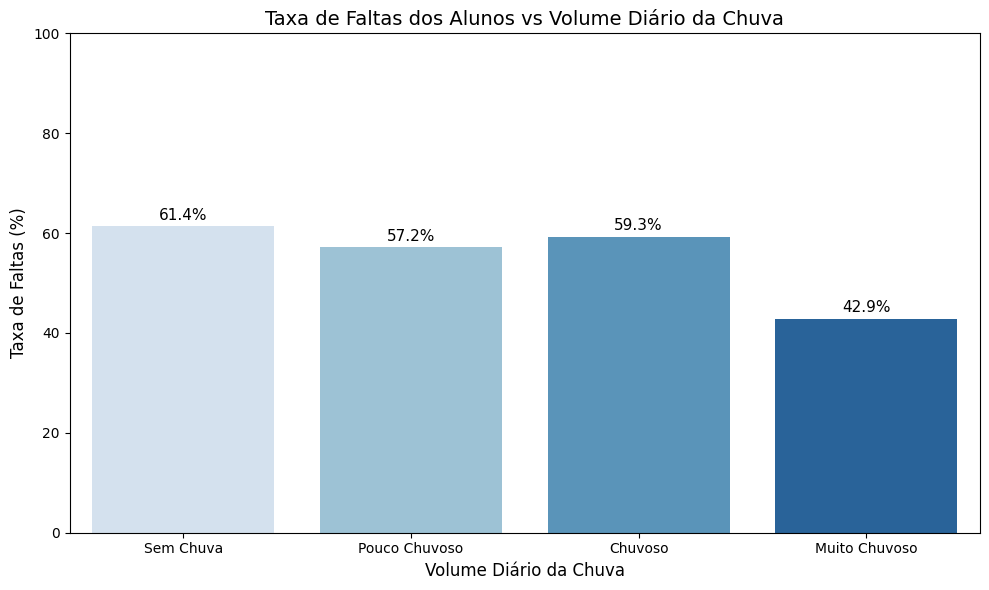

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular a taxa de faltas (Presenca == 0) por volume de chuva
# Use observed=False to ensure all categories are included, even if not present in the data
resumo_faltas = df_micro.groupby('Volume_Chuva', observed=False)['Presenca'].apply(lambda x: (x == 0).mean() * 100).reset_index(name='Taxa de Faltas (%)')

# Fill NaN values (for categories with no data) with 0, which might occur if a category has 0 entries
resumo_faltas['Taxa de Faltas (%)'] = resumo_faltas['Taxa de Faltas (%)'].fillna(0)

print("Taxa de Faltas por Volume Diário da Chuva:")
display(resumo_faltas)

# Plotar o gráfico
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=resumo_faltas, x='Volume_Chuva', y='Taxa de Faltas (%)', hue='Volume_Chuva', palette='Blues', legend=False)
plt.title('Taxa de Faltas dos Alunos vs Volume Diário da Chuva', fontsize=14)
plt.xlabel('Volume Diário da Chuva', fontsize=12)
plt.ylabel('Taxa de Faltas (%)', fontsize=12)
plt.ylim(0, 100)

# Adicionar os valores em cima das barras
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 8),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### Análise Exploratória: Taxa de Faltas vs Temperatura Máxima

Agora vamos investigar se as temperaturas influenciam a taxa de faltas. Vamos agrupar a Temperatura Máxima Diária em faixas (como Frio, Ameno, Quente) e visualizar a proporção de alunos que faltam em cada condição.

Taxa de Faltas por Faixa de Temperatura Máxima:


,Faixa_Temperatura,Taxa de Faltas (%)
0,< 20°C (Frio),53.686636
1,20-25°C (Ameno),57.440476
2,25-30°C (Quente),61.309524
3,30-35°C (Muito Quente),61.706349
4,> 35°C (Extremo),88.095238


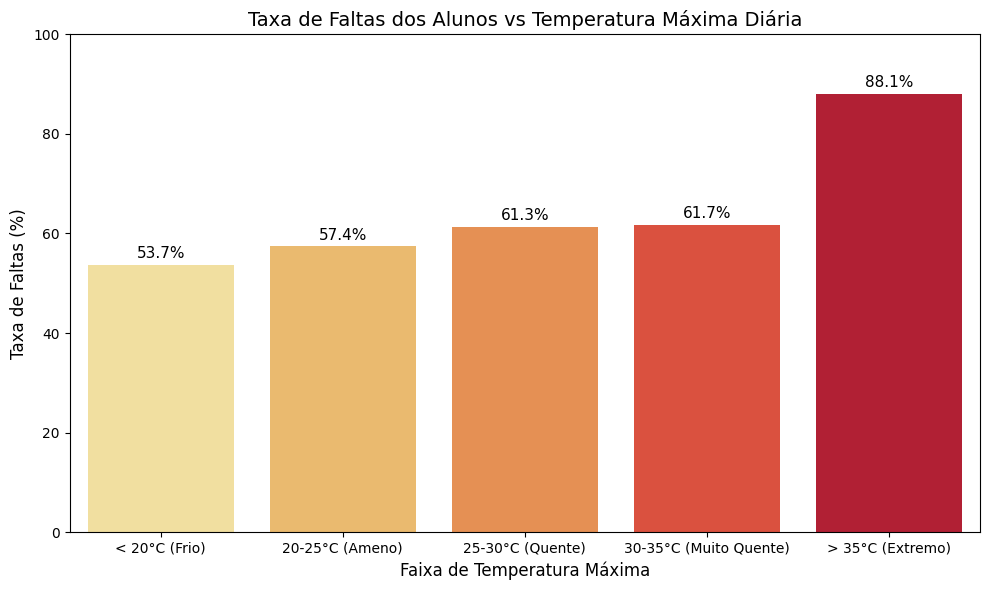

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Criando faixas de temperatura máxima para análise
bins = [0, 20, 25, 30, 35, 50]
labels = ['< 20°C (Frio)', '20-25°C (Ameno)', '25-30°C (Quente)', '30-35°C (Muito Quente)', '> 35°C (Extremo)']
df_micro['Faixa_Temperatura'] = pd.cut(df_micro['Temperatura Max Diaria (°C)'], bins=bins, labels=labels)

# Calcular a taxa de faltas (Presenca == 0) por faixa de temperatura
resumo_temp = df_micro.groupby('Faixa_Temperatura', observed=False)['Presenca'].apply(lambda x: (x == 0).mean() * 100).reset_index(name='Taxa de Faltas (%)')

print("Taxa de Faltas por Faixa de Temperatura Máxima:")
display(resumo_temp.dropna())

# Plotar o gráfico
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=resumo_temp.dropna(), x='Faixa_Temperatura', y='Taxa de Faltas (%)', hue='Faixa_Temperatura', palette='YlOrRd', legend=False)
plt.title('Taxa de Faltas dos Alunos vs Temperatura Máxima Diária', fontsize=14)
plt.xlabel('Faixa de Temperatura Máxima', fontsize=12)
plt.ylabel('Taxa de Faltas (%)', fontsize=12)
plt.ylim(0, 100)

# Adicionar os valores em cima das barras
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 8),
                textcoords='offset points')

plt.tight_layout()
plt.show()


### Preparação dos Dados para Machine Learning

Nesta etapa, vamos preparar a matriz `df_micro` para treinar um modelo preditivo.
Passos:
1. Extrair o `Dia da Semana` e o `Mês` da data.
2. Remover colunas de data originais e identificadores que não devem ser usados diretamente (ou que causam vazamento de dados).
3. Aplicar *One-Hot Encoding* usando `pd.get_dummies()` nas variáveis categóricas.
4. Separar o conjunto em `X` (features) e `y` (target/alvo).

In [136]:
import pandas as pd

print("Iniciando a preparação dos dados (atualizado com a nova métrica de volume)...")

# 1. Extrair features temporais da data
df_ml = df_micro.copy()
df_ml['Dia_da_Semana'] = df_ml['Data Visita'].dt.dayofweek # 0=Segunda, 6=Domingo
df_ml['Mes'] = df_ml['Data Visita'].dt.month

# 2. Definir a variável alvo (y) e as features (X)
# Vamos remover 'Data Visita', 'Data Clima' (redundante)
colunas_para_remover = ['Data Visita', 'Data Clima']
df_ml = df_ml.drop(columns=colunas_para_remover)

# 3. Tratar valores nulos residuais (caso algum dia não tenha dado climático)
# Converter colunas categóricas para 'object' (texto) para permitir o preenchimento
for col in df_ml.select_dtypes(include=['category']).columns:
    df_ml[col] = df_ml[col].astype('object')

df_ml = df_ml.fillna(0)

# Separar X e y
y = df_ml['Presenca']
X_raw = df_ml.drop(columns=['Presenca'])

# 4. Aplicar One-Hot Encoding nas variáveis categóricas
colunas_categoricas_desejadas = ['ID', 'Volume_Chuva', 'Faixa_Temperatura', 'Dia_da_Semana', 'Mes']
# Filtrar apenas as colunas que estão presentes no X_raw
colunas_categoricas = [col for col in colunas_categoricas_desejadas if col in X_raw.columns]

X = pd.get_dummies(X_raw, columns=colunas_categoricas, drop_first=True)

# Garantir que todas as colunas booleanas geradas pelo get_dummies sejam inteiros (0 e 1)
for col in X.select_dtypes(include=['bool']).columns:
    X[col] = X[col].astype(int)

print("\nPreparação concluída!")
print(f"Tamanho original: {df_ml.shape}")
print(f"Tamanho do conjunto de features (X) após Encoding: {X.shape}")

print("\nPrimeiras 5 linhas das features (X) prontas para o modelo:")
display(X.head())

Iniciando a preparação dos dados (atualizado com a nova métrica de volume)...

Preparação concluída!
Tamanho original: (5110, 11)
Tamanho do conjunto de features (X) após Encoding: (5110, 42)

Primeiras 5 linhas das features (X) prontas para o modelo:


,Precipitacao Diaria (mm),Temperatura Max Diaria (°C),Temperatura Min Diaria (°C),Umidade Min Diaria (%),Choveu,ID_ALU002,ID_ALU003,ID_ALU004,ID_ALU005,ID_ALU006,...,Mes_3,Mes_4,Mes_5,Mes_6,Mes_7,Mes_8,Mes_9,Mes_10,Mes_11,Mes_12
0,4.8,30.9,18.4,52,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,4.8,30.9,18.4,52,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4.8,30.9,18.4,52,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,4.8,30.9,18.4,52,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4.8,30.9,18.4,52,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Treinamento e Avaliação do Modelo de Machine Learning (Random Forest)

Vamos dividir os dados em Treino (70%) e Teste (30%). O modelo escolhido para iniciar será o `RandomForestClassifier`, que lida muito bem com dados não-lineares e categorias.

Ao final, usaremos a matriz de confusão e o relatório de classificação para medir:
- **Acurácia:** Qual a taxa de acerto geral.
- **Precisão:** Quando o modelo diz que o aluno vai faltar, qual a chance de estar certo?
- **Recall:** De todas as faltas reais, quantas o modelo conseguiu prever?

Dividindo os dados em conjuntos de Treino e Teste...
Tamanho do Treino: 3577 amostras
Tamanho do Teste: 1533 amostras

Re-treinando o modelo Random Forest (com nova métrica de chuva)...
Modelo treinado com sucesso! Realizando previsões no conjunto de teste...

--- RESULTADOS DA AVALIAÇÃO ---
Acurácia do Modelo: 66.54%

Relatório de Classificação:
              precision    recall  f1-score   support

   Falta (0)       0.71      0.73      0.72       907
Presença (1)       0.59      0.58      0.58       626

    accuracy                           0.67      1533
   macro avg       0.65      0.65      0.65      1533
weighted avg       0.66      0.67      0.66      1533



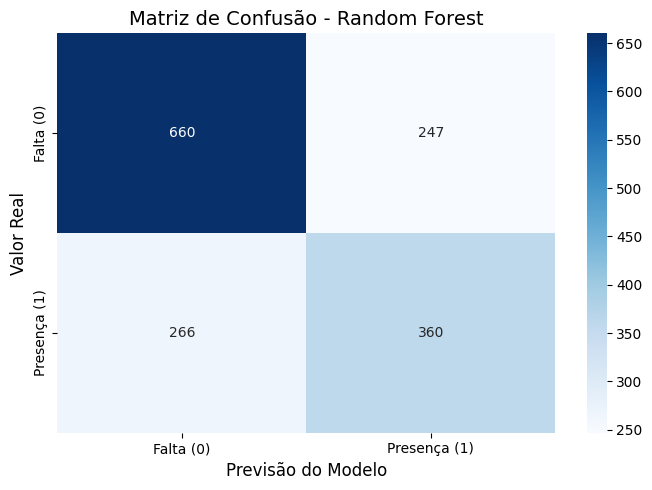

In [137]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Dividindo os dados em conjuntos de Treino e Teste...")
# Dividir 70% para treino e 30% para teste.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Tamanho do Treino: {X_train.shape[0]} amostras")
print(f"Tamanho do Teste: {X_test.shape[0]} amostras\n")

print("Re-treinando o modelo Random Forest (com nova métrica de chuva)...")
# Instanciar e treinar o modelo
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

print("Modelo treinado com sucesso! Realizando previsões no conjunto de teste...\n")
# Fazer previsões no conjunto de teste
y_pred = rf_model.predict(X_test)

# Avaliar os resultados
acuracia = accuracy_score(y_test, y_pred)
print(f"--- RESULTADOS DA AVALIAÇÃO ---")
print(f"Acurácia do Modelo: {acuracia * 100:.2f}%\n")

print("Relatório de Classificação:")
# target_names: 0 = Falta, 1 = Presenca
print(classification_report(y_test, y_pred, target_names=['Falta (0)', 'Presença (1)']))

# Plotar a Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Falta (0)', 'Presença (1)'],
            yticklabels=['Falta (0)', 'Presença (1)'])
plt.title('Matriz de Confusão - Random Forest', fontsize=14)
plt.xlabel('Previsão do Modelo', fontsize=12)
plt.ylabel('Valor Real', fontsize=12)
plt.tight_layout()
plt.show()


### Importância das Variáveis (Feature Importance)

Vamos visualizar quais fatores (chuva, temperatura, ID do aluno, mês) tiveram o maior peso na decisão do nosso modelo Random Forest.

Gerando o gráfico de Importância das Variáveis (Random Forest atualizado)...


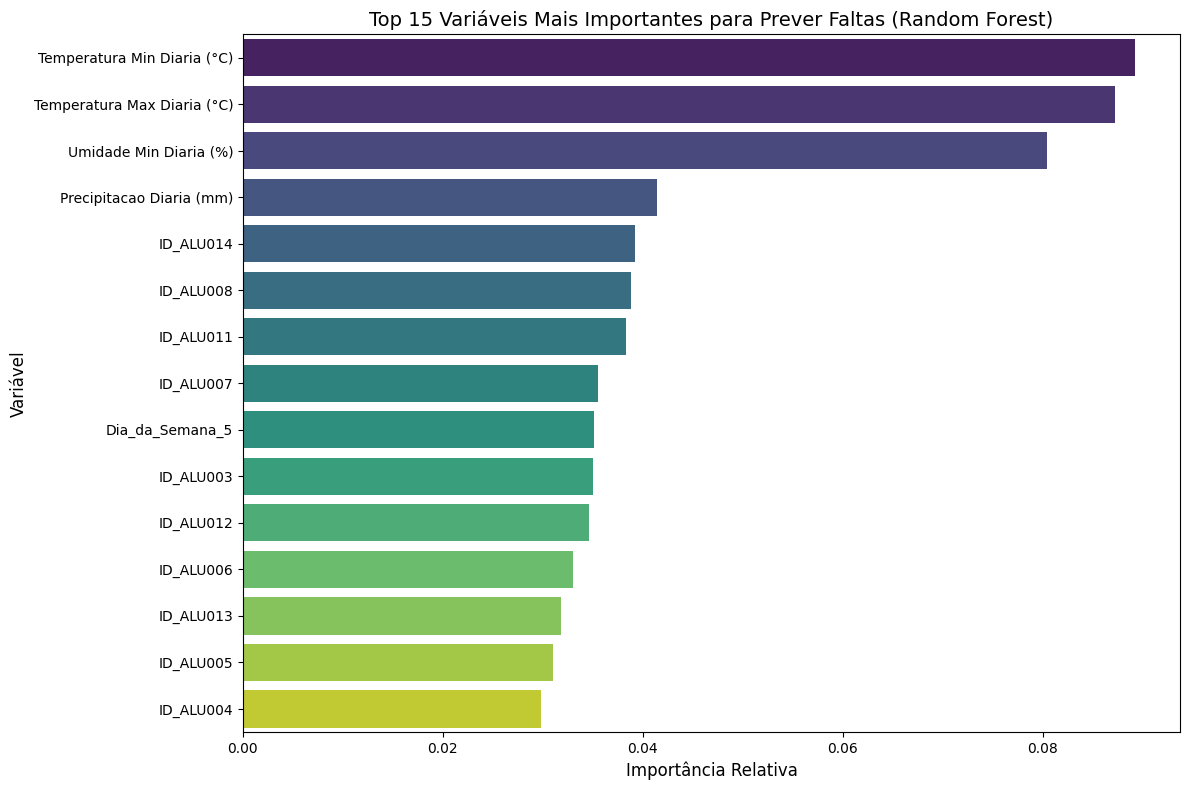

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Gerando o gráfico de Importância das Variáveis (Random Forest atualizado)...")
importancias = rf_model.feature_importances_
features_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importância': importancias
}).sort_values(by='Importância', ascending=False)

plt.figure(figsize=(12, 8))
# Ajuste usando hue='Feature' e legend=False para evitar warnings do Seaborn
sns.barplot(data=features_df.head(15), x='Importância', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 15 Variáveis Mais Importantes para Prever Faltas (Random Forest)', fontsize=14)
plt.xlabel('Importância Relativa', fontsize=12)
plt.ylabel('Variável', fontsize=12)
plt.tight_layout()
plt.show()


### Testando Novos Modelos: Regressão Logística e XGBoost

Agora vamos treinar mais dois modelos para ver se conseguimos melhorar nossa taxa de acerto.
1. **Regressão Logística:** Modelo linear clássico, mais simples e interpretável.
2. **XGBoost:** Modelo baseado em árvores e *Gradient Boosting*, costuma apresentar excelente performance.

Re-treinando o modelo de Regressão Logística (com nova métrica de chuva)...

--- RESULTADOS: REGRESSÃO LOGÍSTICA ---
Acurácia do Modelo: 67.91%

Relatório de Classificação:
              precision    recall  f1-score   support

   Falta (0)       0.71      0.77      0.74       907
Presença (1)       0.62      0.54      0.58       626

    accuracy                           0.68      1533
   macro avg       0.67      0.66      0.66      1533
weighted avg       0.67      0.68      0.68      1533



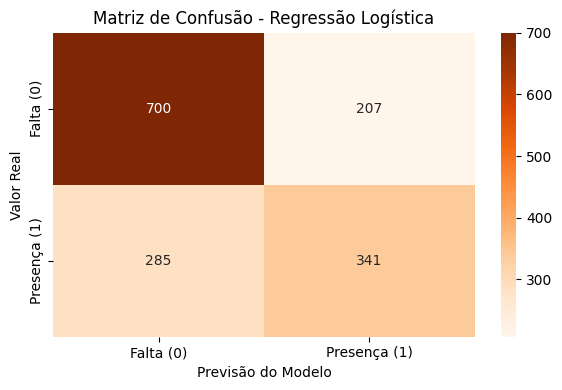

In [139]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("Re-treinando o modelo de Regressão Logística (com nova métrica de chuva)...")
# max_iter=1000 ajuda o algoritmo a convergir (terminar o cálculo) sem erros
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"\n--- RESULTADOS: REGRESSÃO LOGÍSTICA ---")
print(f"Acurácia do Modelo: {acc_lr * 100:.2f}%\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred_lr, target_names=['Falta (0)', 'Presença (1)']))

cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Falta (0)', 'Presença (1)'],
            yticklabels=['Falta (0)', 'Presença (1)'])
plt.title('Matriz de Confusão - Regressão Logística', fontsize=12)
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()


Re-treinando o modelo XGBoost (com nova métrica de chuva)...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:27:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



--- RESULTADOS: XGBOOST ---
Acurácia do Modelo: 70.65%

Relatório de Classificação:
              precision    recall  f1-score   support

   Falta (0)       0.75      0.76      0.75       907
Presença (1)       0.64      0.63      0.64       626

    accuracy                           0.71      1533
   macro avg       0.70      0.70      0.70      1533
weighted avg       0.71      0.71      0.71      1533



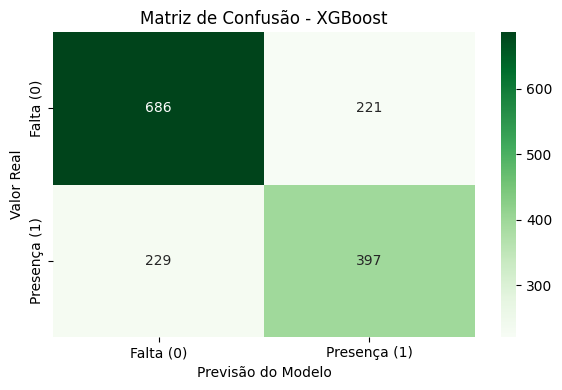

In [140]:
import xgboost as xgb
import re

print("Re-treinando o modelo XGBoost (com nova métrica de chuva)...")
# O XGBoost não suporta caracteres como [, ], < ou > nos nomes das colunas.
# Vamos renomear as colunas no X_train e X_test para o XGBoost
X_train_xgb = X_train.rename(columns=lambda x: re.sub(r'[\[\]<>]', '_', x))
X_test_xgb = X_test.rename(columns=lambda x: re.sub(r'[\[\]<>]', '_', x))

# eval_metric evita alguns avisos em versões mais recentes do XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train_xgb, y_train)

y_pred_xgb = xgb_model.predict(X_test_xgb)
acc_xgb = accuracy_score(y_test, y_pred_xgb)

print(f"\n--- RESULTADOS: XGBOOST ---")
print(f"Acurácia do Modelo: {acc_xgb * 100:.2f}%\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred_xgb, target_names=['Falta (0)', 'Presença (1)']))

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Falta (0)', 'Presença (1)'],
            yticklabels=['Falta (0)', 'Presença (1)'])
plt.title('Matriz de Confusão - XGBoost', fontsize=12)
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()


In [141]:
import os

# Caminho para salvar o arquivo
drive_path_save = '/content/drive/MyDrive/Projeto Integrador IV/Dados/INMET'
file_name_micro = 'dados_inmet_interlagos_tratados_combinados_1.csv'
file_path_micro = os.path.join(drive_path_save, file_name_micro)

print(f"Salvando a matriz de presenças atualizada (df_micro) em: {file_path_micro}")
df_micro.to_csv(file_path_micro, index=False, encoding='utf-8')
print("Arquivo salvo com sucesso e pronto para uso futuro!")

Salvando a matriz de presenças atualizada (df_micro) em: /content/drive/MyDrive/Projeto Integrador IV/Dados/INMET/dados_inmet_interlagos_tratados_combinados_1.csv
Arquivo salvo com sucesso e pronto para uso futuro!


Gerando Mapa de Calor de Correlações...


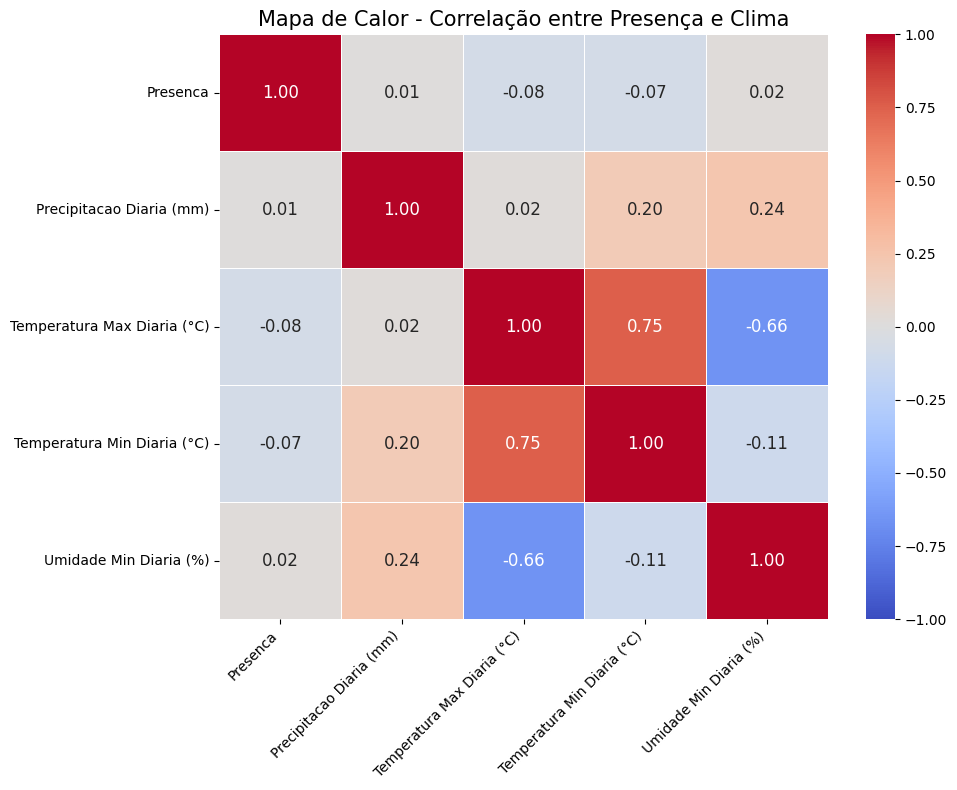

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Gerando Mapa de Calor de Correlações...")

# Selecionar as colunas numéricas de interesse para a correlação
colunas_correlacao = [
    'Presenca',
    'Precipitacao Diaria (mm)',
    'Temperatura Max Diaria (°C)',
    'Temperatura Min Diaria (°C)',
    'Umidade Min Diaria (%)'
]

# Garantir que as colunas existem no DataFrame
colunas_existentes = [col for col in colunas_correlacao if col in df_micro.columns]

# Calcular a matriz de correlação
matriz_corr = df_micro[colunas_existentes].corr()

# Configurar e plotar o heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 12})

plt.title('Mapa de Calor - Correlação entre Presença e Clima', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()